In [ ]:
!pip install pmdarima -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 2.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera, norm, skew, kurtosis
from pmdarima import auto_arima
from statsmodels.tsa.arima_process import ArmaProcess
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import statsmodels.api as sm

In [ ]:
# Tentukan simbol saham (ticker)
ticker = '^JKSE'

# Unduh data historis berdasarkan tanggal spesifik (format YYYY-MM-DD)
data = yf.download(ticker, start='2025-08-28', end='2026-09-17')

# Tampilkan 5 baris pertama
data.head()

/tmp/ipykernel_2018/1316413775.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start='2025-08-28', end='2026-09-17')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^JKSE,^JKSE,^JKSE,^JKSE,^JKSE
Date,,,,,
2025-08-28,7952.087891,8022.757812,7941.938965,7951.865234,399326600
2025-08-29,7830.493164,7913.859863,7765.596191,7899.887207,481348100
2025-09-01,7736.065918,7783.417969,7547.563965,7620.099121,358661000
2025-09-02,7801.584961,7842.298828,7771.333984,7771.333984,347812700
2025-09-03,7885.862793,7911.618164,7840.750977,7843.631836,351685500


In [ ]:
# Mengambil hanya kolom 'Close'
df = data[['Close']]

# Menampilkan 5 baris pertama kolom Close
print(df.tail())

Price             Close
Ticker            ^JKSE
Date                   
2026-09-10  6589.337891
2026-09-11  6541.376953
2026-09-14  6534.692871
2026-09-15  6461.152832
2026-09-16  6436.853027


## Statistika Deskriptif

In [ ]:
df.describe()

Price,Close
Ticker,^JKSE
count,252.000000
mean,7457.810907
std,1005.642617
min,5342.137207
25%,6446.585815
50%,7687.479004
75%,8274.534668
max,9134.700195


## Time Series Plot

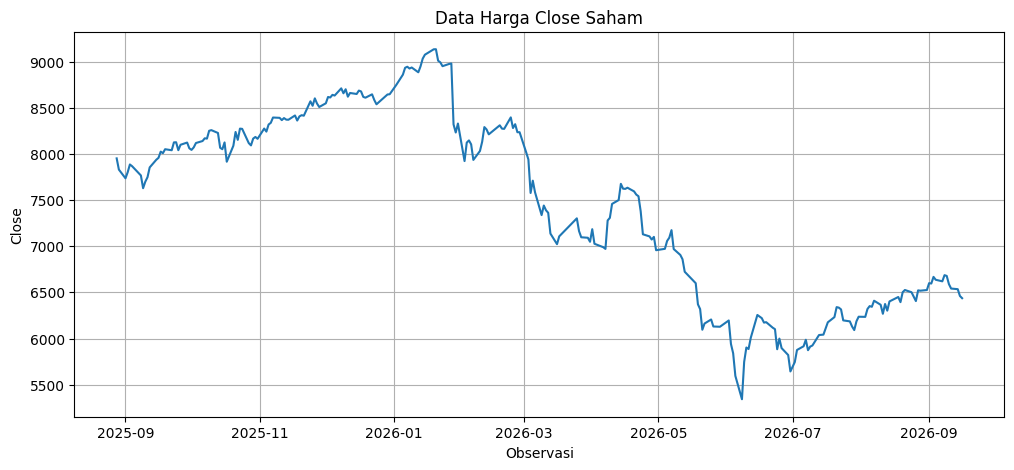

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df)
plt.title("Data Harga Close Saham")
plt.xlabel("Observasi")
plt.ylabel("Close")
plt.grid()
plt.show()

## UJI ADF

In [ ]:
def adf_test(df):
    hasil = adfuller(df)

    print("ADF Statistic :", hasil[0])
    print("p-value       :", hasil[1])
    print("Critical Value:")

    for key, value in hasil[4].items():
        print(f"   {key} : {value}")

    if hasil[1] < 0.05:
        print("\nKesimpulan: Data STASIONER")
    else:
        print("\nKesimpulan: Data BELUM STASIONER")

adf_test(df)

ADF Statistic : -0.8157573955239896
p-value       : 0.8144495762580175
Critical Value:
   1% : -3.4569962781990573
   5% : -2.8732659015936024
   10% : -2.573018897632674

Kesimpulan: Data BELUM STASIONER


/tmp/ipykernel_2018/3885212564.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(df)


## Differencing

In [ ]:
df_diff = df.diff().dropna()

print("Data setelah differencing:")
print(df_diff.head())

Data setelah differencing:
Price            Close
Ticker           ^JKSE
Date                  
2025-08-29 -121.594727
2025-09-01  -94.427246
2025-09-02   65.519043
2025-09-03   84.277832
2025-09-04  -18.514648


## Uji ADF setelah Differencing

In [ ]:
adf_test(df_diff)

ADF Statistic : -7.594649139746433
p-value       : 2.4788213934805048e-11
Critical Value:
   1% : -3.4569962781990573
   5% : -2.8732659015936024
   10% : -2.573018897632674

Kesimpulan: Data STASIONER


/tmp/ipykernel_2018/3885212564.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(df)


## Visualisasi ACF & PACF

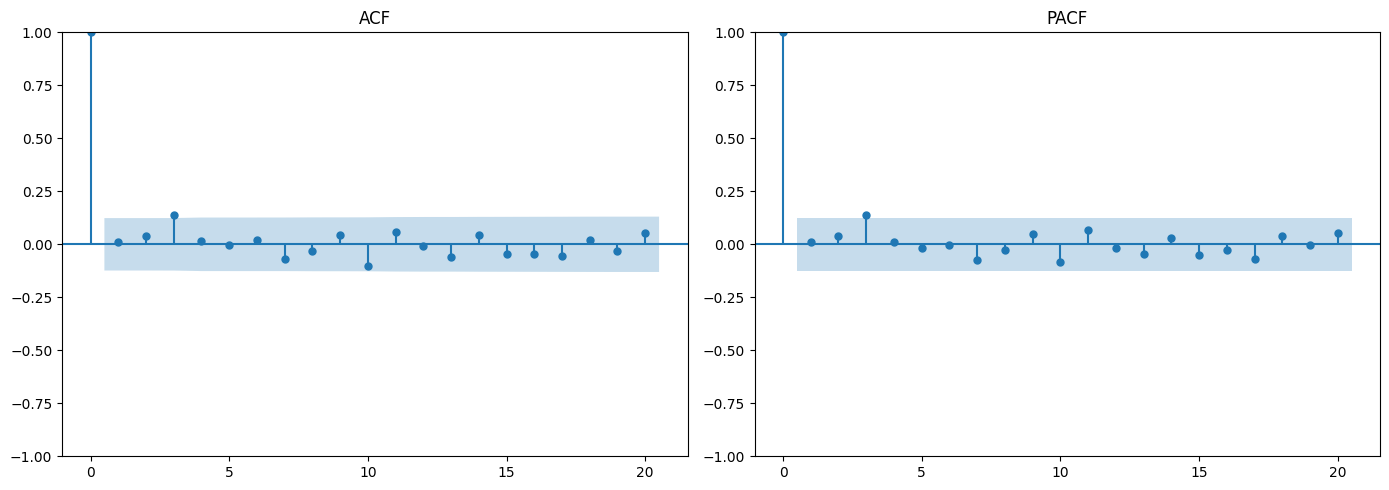

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))

plot_acf(df_diff["Close"], lags=20, ax=ax[0])
ax[0].set_title("ACF")

plot_pacf(df_diff["Close"], lags=20, ax=ax[1], method='ywm')
ax[1].set_title("PACF")

plt.tight_layout()
plt.show()

## Estimasi Parameter

In [ ]:
# Daftar kandidat orde model ARIMA (p, d, q) berdasarkan plot ACF dan PACF
candidate_orders = [(0, 1, 0), (3, 1, 0), (0, 1, 3), (3, 1, 3)]

results = []

# Iterasi fitting model untuk setiap kandidat
for order in candidate_orders:
    try:
        # Pemasangan model ARIMA pada data Close tingkat asli (d=1 ditangani otomatis oleh fungsi)
        model = ARIMA(data['Close'], order=order)
        model_fit = model.fit()

        # Menyimpan metrik evaluasi kriteria kebaikan model
        results.append({
            'Model': f'ARIMA{order}',
            'AIC': model_fit.aic,
            'BIC': model_fit.bic,
            'Log-Likelihood': model_fit.llf
        })

        # Cetak rincian estimasi parameter (koefisien, std error, p-value)
        print(f"==================== RINGKASAN PARAMETER ARIMA{order} ====================")
        print(model_fit.summary())
        print("\n")

    except Exception as e:
        print(f"Model ARIMA{order} gagal dieksekusi: {e}")

# Membuat tabel perbandingan nilai AIC dan BIC seluruh kandidat model
df_comparison = pd.DataFrame(results)
print("==================== TABEL PERBANDINGAN MODEL ====================")
print(df_comparison.sort_values(by='AIC').reset_index(drop=True))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

==================== RINGKASAN PARAMETER ARIMA(0, 1, 0) ====================
                               SARIMAX Results                                
Dep. Variable:                  ^JKSE   No. Observations:                  252
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -1536.930
Date:                Wed, 21 Oct 2026   AIC                           3075.861
Time:                        15:25:55   BIC                           3079.386
Sample:                             0   HQIC                          3077.280
                                - 252                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      1.219e+04    548.949     22.211      0.000    1.11e+04    1.33e+04
Ljung-Box (L1) (Q):                   0.04   Jarque-Be

## Diagnosis Residual

### Uji Normalitas

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


==================== HASIL UJI JARQUE-BERA ====================
Statistik Jarque-Bera : 360.7842
p-value               : 0.0000
Skewness              : -0.8510
Kurtosis              : 5.6214


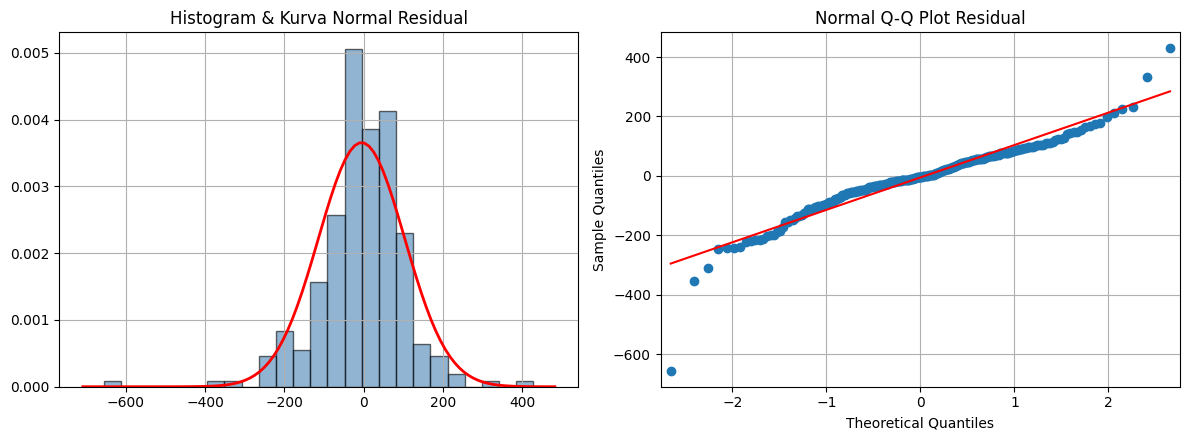

In [ ]:
# 1. Fitting model ARIMA(3, 1, 0)
model = ARIMA(data['Close'], order=(3, 1, 0))
model_fit = model.fit()

# 2. Ambil residual dan buang titik awal (artefak differencing)
residuals = model_fit.resid.iloc[1:]

# 3. Hitung Uji Jarque-Bera, Skewness, dan Kurtosis secara terpisah
jb_stat, jb_pvalue = jarque_bera(residuals)
skew_val = skew(residuals)
kurt_val = kurtosis(residuals)  # excess kurtosis

print("==================== HASIL UJI JARQUE-BERA ====================")
print(f"Statistik Jarque-Bera : {jb_stat:.4f}")
print(f"p-value               : {jb_pvalue:.4f}")
print(f"Skewness              : {skew_val:.4f}")
print(f"Kurtosis              : {kurt_val:.4f}")

# 4. Visualisasi Histogram dan Normal Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Histogram & Kurva Normal
axes[0].hist(residuals, bins=25, density=True, alpha=0.6, color='steelblue', edgecolor='black')
xmin, xmax = axes[0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, np.mean(residuals), np.std(residuals))
axes[0].plot(x, p, 'r', linewidth=2)
axes[0].set_title('Histogram & Kurva Normal Residual')
axes[0].grid(True)

# Plot 2: Normal Q-Q Plot
sm.qqplot(residuals, line='s', ax=axes[1])
axes[1].set_title('Normal Q-Q Plot Residual')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Uji Autokorelasi

==================== HASIL UJI LJUNG-BOX ====================
     lb_stat  lb_pvalue
5   0.158989   0.999493
10  3.950296   0.949561
15  6.528716   0.969434
20  9.256127   0.979746


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


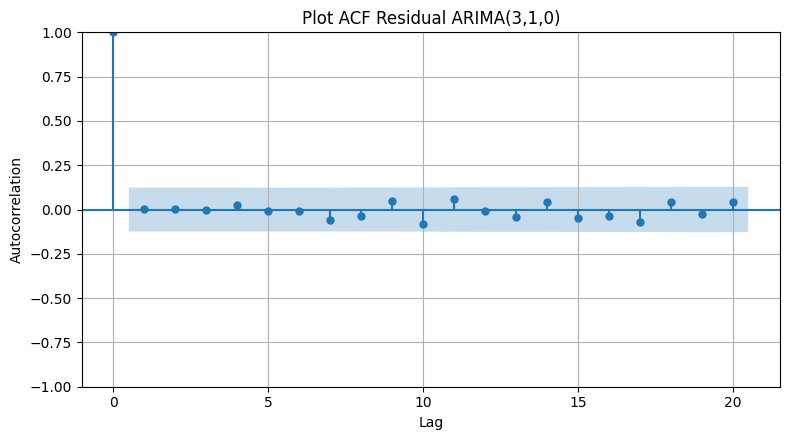

In [ ]:
# 1. Fitting model ARIMA(3, 1, 0)
model = ARIMA(data['Close'], order=(3, 1, 0))
model_fit = model.fit()

# 2. Ambil residual dan buang titik awal (artefak differencing)
residuals = model_fit.resid.iloc[1:]

# 3. Hitung Uji Ljung-Box pada lag 5, 10, 15, dan 20
ljung_box_results = acorr_ljungbox(residuals, lags=[5, 10, 15, 20], return_df=True)

print("==================== HASIL UJI LJUNG-BOX ====================")
print(ljung_box_results)

# 4. Visualisasi Plot Autokorelasi (ACF) Residual
plt.figure(figsize=(8, 4.5))
sm.graphics.tsa.plot_acf(residuals, lags=20, ax=plt.gca(), title='Plot ACF Residual ARIMA(3,1,0)')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.tight_layout()
plt.show()

## Uji Heteroskedastisitas

In [ ]:
# 1. Fitting model ARIMA(3, 1, 0)
model = ARIMA(data['Close'], order=(3, 1, 0))
model_fit = model.fit()

# 2. Ambil residual dan buang titik awal (artefak differencing)
residuals = model_fit.resid.iloc[1:]

# 3. Uji ARCH-LM pada lag 5
lm_stat, p_value, f_stat, f_pvalue = het_arch(residuals, maxlag=5)

print("==================== HASIL UJI ARCH-LM ====================")
print(f"LM Statistic : {lm_stat:.4f}")
print(f"p-value (LM) : {p_value:.4f}")
print(f"F Statistic  : {f_stat:.4f}")
print(f"p-value (F)  : {f_pvalue:.4f}")

==================== HASIL UJI ARCH-LM ====================
LM Statistic : 9.4762
p-value (LM) : 0.0915
F Statistic  : 1.9231
p-value (F)  : 0.0912


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default be

## Forecasting

==================== HASIL PERAMALAN IHSG ====================
            Hasil Peramalan  Batas Bawah (95%)  Batas Atas (95%)
2026-09-17      6433.167226        6218.858688       6647.475764
2026-09-18      6421.771934        6118.026392       6725.517476
2026-09-21      6418.116762        6041.359412       6794.874112
2026-09-22      6417.167302        5963.008382       6871.326222
2026-09-23      6415.403826        5894.971189       6935.836463
2026-09-24      6414.839706        5834.703148       6994.976265
2026-09-25      6414.638594        5778.595308       7050.681879
2026-09-28      6414.365504        5726.880896       7101.850112
2026-09-29      6414.276490        5678.772972       7149.780007
2026-09-30      6414.237608        5633.449118       7195.026097


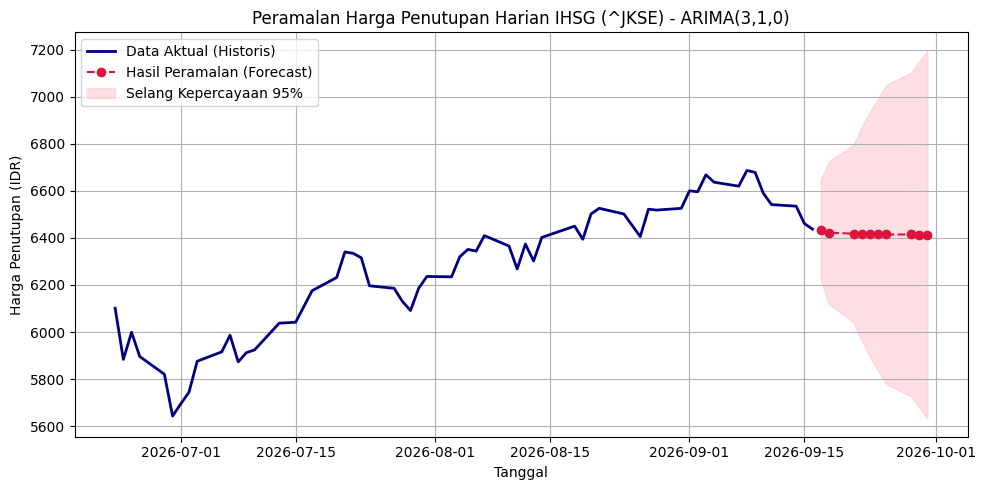

In [ ]:
# Pastikan indeks data bertipe DatetimeIndex
data.index = pd.to_datetime(data.index)

# 1. Fitting model ARIMA(3, 1, 0) menggunakan .values untuk menghindari error frekuensi indeks
model = ARIMA(data['Close'].values, order=(3, 1, 0))
model_fit = model.fit()

# 2. Tentukan horizon peramalan (10 hari kerja ke depan)
forecast_steps = 10

# 3. Ekstraksi hasil peramalan beserta Confidence Interval (CI 95%)
forecast_obj = model_fit.get_forecast(steps=forecast_steps)
forecast_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int(alpha=0.05)

# Buat indeks tanggal manual khusus hari kerja (bdate_range) mulai hari kerja berikutnya
last_date = data.index[-1]
forecast_index = pd.bdate_range(start=last_date + pd.Timedelta(days=1), periods=forecast_steps)

# Buat DataFrame rangkuman hasil peramalan
df_forecast = pd.DataFrame({
    'Hasil Peramalan': forecast_mean,
    'Batas Bawah (95%)': conf_int[:, 0],
    'Batas Atas (95%)': conf_int[:, 1]
}, index=forecast_index)

print("==================== HASIL PERAMALAN IHSG ====================")
print(df_forecast)

# 4. Visualisasi Plot Hasil Peramalan
plt.figure(figsize=(10, 5))

# Tampilkan 60 data historis terakhir agar grafik fokus
historical_data = data['Close'].iloc[-60:]

plt.plot(historical_data.index, historical_data.values, label='Data Aktual (Historis)', color='navy', lw=2)
plt.plot(df_forecast.index, df_forecast['Hasil Peramalan'], label='Hasil Peramalan (Forecast)', color='crimson', linestyle='--', marker='o')

# Area Selang Kepercayaan 95%
plt.fill_between(
    df_forecast.index,
    df_forecast['Batas Bawah (95%)'],
    df_forecast['Batas Atas (95%)'],
    color='pink', alpha=0.5, label='Selang Kepercayaan 95%'
)

plt.title('Peramalan Harga Penutupan Harian IHSG (^JKSE) - ARIMA(3,1,0)', fontsize=12)
plt.xlabel('Tanggal')
plt.ylabel('Harga Penutupan (IDR)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluasi

In [ ]:
# 1. Fitting model ARIMA(3, 1, 0)
model = ARIMA(data['Close'].values, order=(3, 1, 0))
model_fit = model.fit()

# 2. Ambil nilai aktual dan nilai prediksi in-sample (fitted values)
# Membuang baris pertama (.iloc[1:]) untuk menghindari artefak kondisi awal differencing
y_true = data['Close'].iloc[1:].values
y_pred = model_fit.fittedvalues[1:]

# 3. Hitung MAE, RMSE, dan MAPE
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = mean_absolute_percentage_error(y_true, y_pred) * 100  # Dikonversi ke persen (%)

print("==================== EVALUASI AKURASI MODEL ====================")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.4f}%")

==================== EVALUASI AKURASI MODEL ====================
MAE  : 76.6658
RMSE : 109.1957
MAPE : 1.0678%
